# V13: Gemma-only answer-order averaging

The persistent goal is rank19 or better on the actual Kaggle leaderboard. The
retained official score is0.83053; lower multiclass log loss is better. V12kept
8192packing and stopped Llama-only order averaging at its fixed information gate.
This span tests one complementary recipe, frozen before examining its replay.

Original Gemma2-9B and swapped Llama3-8B retain equal total expert weights. On the
unchanged label-free disagreement-per-token-work route (max10%work,20%rows):

    .25 Gemma_original + .25 aligned_Gemma_swapped + .5 aligned_Llama_swapped

Off-route retain the original equal ensemble. Temperature1, context4096, fp16,
8192packing, author kernels/pinned Python3.10image. No route, weight, temperature
or leaderboard search. Original votes overlap checkpoint training: cached and
repeated local metrics are descriptive, not independent CV or official forecasts.
The gain>0.0005information gate only permits actual deployment qualification.

,cohort,rows,selected_rows,baseline_log_loss,candidate_log_loss,loss_reduction,descriptive_paired_group95,baseline_accuracy,candidate_accuracy
0,control,256,42,0.599429,0.598234,0.001194,"[-0.001008, 0.003169]",0.773438,0.773438
1,uniform,512,83,0.654242,0.652988,0.001254,"[-0.000039, 0.00262]",0.750000,0.751953
2,long,64,6,0.896528,0.896484,0.000043,"[-0.003324, 0.003033]",0.609375,0.609375


,control,uniform,long
winner_model_a,0.002753,0.002156,3.845667e-03
winner_model_b,0.000720,0.000227,-3.273113e-03
winner_tie,-0.000194,0.001290,1.496520e-08


Information gate passed: True
Independent local quality: False
Official result is needed to assess competition transfer.


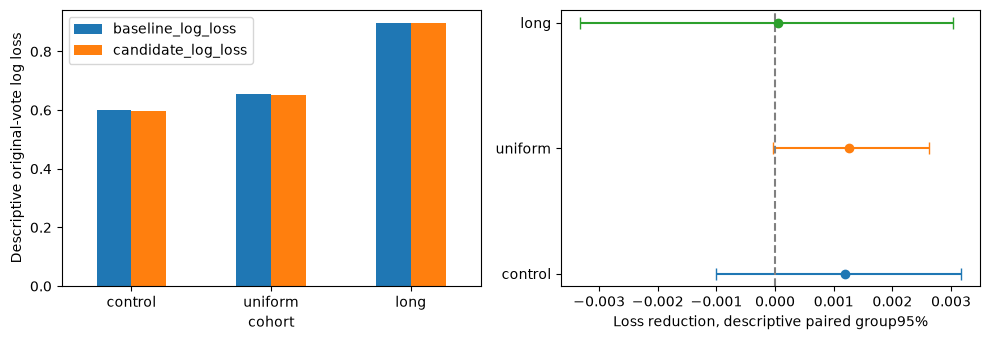

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_013'
def read(name):return json.loads((PUB/name).read_text())
replay=read('H60_cached_replay.json');phase=read('span_plan.json')
rows=[{'cohort':name,**value} for name,value in replay['coverage'].items() if name!='test']
display(pd.DataFrame(rows)[['cohort','rows','selected_rows','baseline_log_loss','candidate_log_loss',
 'loss_reduction','descriptive_paired_group95','baseline_accuracy','candidate_accuracy']])
display(pd.DataFrame({name:value['class_loss_reduction'] for name,value in replay['coverage'].items() if name!='test'}))
print('Information gate passed:',replay['information_gate_passed'])
print('Independent local quality:',replay['independent_local_quality'])
print('Official result is needed to assess competition transfer.')
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
table=pd.DataFrame(rows).set_index('cohort')
table[['baseline_log_loss','candidate_log_loss']].plot.bar(ax=axes[0],rot=0)
axes[0].set_ylabel('Descriptive original-vote log loss')
for i,row in enumerate(rows):
 lo,hi=row['descriptive_paired_group95'];gain=row['loss_reduction']
 axes[1].errorbar(gain,i,xerr=[[max(0,gain-lo)],[max(0,hi-gain)]],fmt='o',capsize=4)
axes[1].axvline(0,color='gray',linestyle='--');axes[1].set_yticks(range(len(rows)),[r['cohort'] for r in rows])
axes[1].set_xlabel('Loss reduction, descriptive paired group95%')
fig.tight_layout();plt.show()

The actual worker uses three inference passes: both base experts, then Gemma
on routed rows only. Each loaded model receives a full80-row warmup. Public control256,
uniform512and long64cohorts retain their historical IDs. Hidden mode performs actual
inference on competition test text, with no public prediction cache or labels.

Require strict raw1e-5controls, exact source/checkpoint/ID/token/swap checks,
correct CSV/simplex and both T4devices. The conservative25krow projection must be
below9hours:20%margin on measured uniform base plus routed-reverse cost, all
cold/full-warmup/other overhead and600sreserve. Initial public cap40minutes,
one separately admitted engineering follow-up up to60minutes, total100minutes;
one quality recipe/one official submission. Missing qualification means pending.

,role,observed_at,status,kernel_version
0,gemma_order,2026-11-07T20:02:20.495899+00:00,COMPLETE,arseniytrushin/llm-preference-span013-gemma-or...


,role,observed_at,stage,rows,seconds,cohort
0,m0_reverse,2026-11-07T20:01:34.866623+00:00,cohort_complete,83,31.781841,routed_uniform


Fixed deadline: 2026-11-09T19:29:48.662254+00:00 ; public phase cap hours: 1.6666666666666667


,role,source,controls_passed,runtime_passed,projection_hours,actual_session_minutes,two_T4,CSV_verified
0,gemma_order,arseniytrushin/llm-preference-span013-gemma-or...,True,True,8.586802,27.631101,True,True


,rows,max_abs_probability_difference,passed
m0,256,0.0,True
m3,256,0.0,True
reverse_control,42,0.0,True
reverse_uniform,83,0.0,True
reverse_long,6,0.0,True
reverse_test,0,0.0,True


,rows,selected_rows,selected_work_fraction,route_replayed,mixture_replayed,independent,baseline_log_loss,candidate_log_loss,loss_reduction,descriptive_paired_group95,class_loss_reduction
control,256,42,0.099494,True,True,False,0.599429,0.598234,0.001194,"[-0.001008, 0.003169]","{'winner_model_a': 0.002753121181803383, 'winn..."
uniform,512,83,0.099805,True,True,False,0.654242,0.652988,0.001254,"[-0.000039, 0.00262]","{'winner_model_a': 0.002156058420739192, 'winn..."
long,64,6,0.089096,True,True,False,0.896528,0.896484,0.000043,"[-0.003324, 0.003033]","{'winner_model_a': 0.0038456665535909675, 'win..."
test,3,0,0.0,True,True,False,NaN,NaN,NaN,NaN,NaN


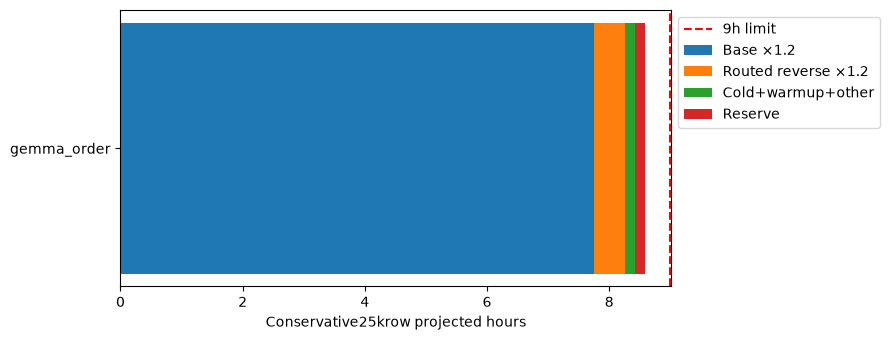

In [2]:
states=[];progress=[]
for role in ['gemma_order','gemma_order_followup']:
 for name,dest in [('status.json',states),('progress.json',progress)]:
  path=PUB/'jobs'/role/name
  if path.exists():
   value=json.loads(path.read_text())
   dest.append({'role':role,'observed_at':value.get('observed_at'),**(value.get('latest',value))})
display(pd.DataFrame(states));display(pd.DataFrame(progress))
print('Fixed deadline:',phase['deadline'],'; public phase cap hours:',phase['gpu_session_seconds_cap']/3600)
qualifications={}
for role in ['gemma_order','gemma_order_followup']:
 path=PUB/(role+'_qualification.json')
 if path.exists():
  q=read(path.name);qualifications[role]=q
  display(pd.DataFrame([{'role':role,'source':q['source']['kernel_version'],'controls_passed':q['all_controls_passed'],
   'runtime_passed':q['runtime_gate_passed'],'projection_hours':q['runtime']['projection_seconds']/3600,
   'actual_session_minutes':q['session_seconds']/60,'two_T4':q['both_t4_verified'],'CSV_verified':q['csv_verified']}]))
  display(pd.DataFrame(q['control_identity']).T)
  display(pd.DataFrame(q['coverage']).T)
if qualifications:
 fig,ax=plt.subplots(figsize=(9,3.5))
 for i,(role,q) in enumerate(qualifications.items()):
  r=q['runtime'];parts={'Base ×1.2':25000*r['base_uniform_seconds']/512*1.2,
   'Routed reverse ×1.2':25000*r['reverse_routed_uniform_seconds']/512*1.2,
   'Cold+warmup+other':r['cold_seconds']+r['full_warmup_seconds']+r['other_seconds'],'Reserve':600}
  left=0
  for label,value in parts.items():
   ax.barh(i,value/3600,left=left,label=label if i==0 else None);left+=value/3600
 ax.axvline(9,color='red',linestyle='--',label='9h limit');ax.set_yticks(range(len(qualifications)),list(qualifications))
 ax.set_xlabel('Conservative25krow projected hours');ax.legend(loc='upper left',bbox_to_anchor=(1,1))
 fig.tight_layout();plt.show()
else:print('Actual deployment qualification pending. Cached gain does not qualify production.')

In [3]:
path=PUB/'deployment_decision.json'
if path.exists():display(read(path.name))
else:print('No deployment decision yet.')
path=PUB/'official_result.json'
if path.exists():
 result=read(path.name)
 display(pd.DataFrame([{k:result.get(k) for k in ['ref','status','public_score','private_score','date']}]))
 if result['status'].endswith('COMPLETE'):
  print('Official change versus retained0.83053:',float(result['public_score'])-.83053)
 else:print('Official scoring pending; no new official score yet.')
else:print('No official submission yet.')
for name in ['official_leaderboard.json','final_leaderboard.json']:
 if (PUB/name).exists():display(pd.DataFrame([read(name)]))
print('Goal completion requires rank<=19on a fresh complete official leaderboard, plus completed reporting.')

{'at': '2026-11-07T20:03:37.387274+00:00',
 'submit': True,
 'role': 'gemma_order',
 'kernel_version': 'arseniytrushin/llm-preference-span013-gemma-order/1',
 'temperature': 1,
 'packing_tokens': 8192,
 'recipe': 'On fixed route: .25 Gemma original + .25 aligned Gemma swapped + .5 aligned Llama swapped; off-route base',
 'parameters_selected_without_leaderboard_feedback': True,
 'independent_local_quality': False,
 'interpretation': 'Training-overlapping descriptive information only; official result tests target transfer',
 'evidence_sha256': {'gemma_order_qualification.json': '925ab812dd16be5aeab1b5c649c773d82722050a73e43d6a672c914ffd68e700',
  'gemma_order_bundle.json': '69e41a6a7ba249d5f6e39d13b5231b5312031973bfb26685177914ee66637b32',
  'gemma_order_source_verification.json': '43994065f4ec14ad78435ba16a200e3c184306aee2647268baddfb8195f1e4b8',
  'H60_cached_replay.json': 'c3b70dbcd779e7fc708df37dfea1ce6255c4831b9de1fe4c5d4dac9d799ff5e7'},
 'projection_seconds': 30912.48602725137}

,ref,status,public_score,private_score,date
0,58103553,SubmissionStatus.PENDING,,,2026-11-07 20:07:11.890000


Official scoring pending; no new official score yet.
Goal completion requires rank<=19on a fresh complete official leaderboard, plus completed reporting.
